# Определение ориентации кропа с текстом

CNN на PyTorch оценивает вероятность поворота текста на 180°. Ноутбук загружает сохранённую модель или при необходимости обучает её, проверяет валидационную выборку, применяет симметричное объединение предсказаний после поворота на 180°, подбирает температуру и создаёт `submission.csv`.

Необходимые файлы:
- `orientation_model.pth` - сохранённые веса, если `TRAIN_MODEL = False`;
- `orientation_dataset/train` и `orientation_dataset/validation` - искусственный датасет;
- `images/test_*.png` - тестовые изображения.

## Краткое описание решения

Используется CNN, обучаемая на искусственных изображениях текста. Для оценки применяются 1 - Brier Score, Brier Score и accuracy. На валидационной выборке проверяется симметричное объединение предсказаний изображения и его поворота на 180°, после чего температура калибровки выбирается по Brier Score. Итоговые вероятности сохраняются в `submission.csv`.

## Что предпринималось

Первым делом генерировался искусственный датасет. В первой версии были просто чёрные надписи на белом фоне. Затем датасет усложнился: добавились цвета, фон, эффекты.

Я начала с похожей на текущую CNN-архитектуры. Затем попробовала MobileNet, но он показал результат похуже. В условиях сильно ограниченного времени вернулась к CNN, хотя рассматривала ещё ResNet.

Далее добавила симметричное предсказание с поворотом на 180°. Так вероятность для исходного изображения объединяется с вероятностью для перевёрнутого.

И затем улучшила калибровку вероятностей с помощью температуры. Пробовала разные коэффициенты, остановилась на значении `T = 0.36`.

In [1]:
from pathlib import Path
import csv
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 64
NUM_EPOCHS = 10
LEARNING_RATE = 0.001
DATASET_DIR = Path("orientation_dataset")
TEST_DIR = Path("images")
MODEL_PATH = Path("orientation_model.pth")
SUBMISSION_PATH = Path("submission.csv")
TRAIN_MODEL = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Преобразования и архитектура

In [2]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.Pad(IMAGE_SIZE, fill=0),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class OrientationCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Linear(256, 1)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

def score_probabilities(probabilities, labels):
    brier = np.mean((probabilities - labels) ** 2)
    accuracy = np.mean((probabilities >= 0.5) == labels)
    return 1.0 - brier, brier, accuracy

train_dir = DATASET_DIR / "train"
val_dir = DATASET_DIR / "validation"
train_dataset = None
val_dataset = None

if train_dir.exists():
    train_dataset = datasets.ImageFolder(train_dir, transform=transform)
    print("Train:", len(train_dataset), train_dataset.class_to_idx)
if val_dir.exists():
    val_dataset = datasets.ImageFolder(val_dir, transform=transform)
    print("Validation:", len(val_dataset), val_dataset.class_to_idx)

Train: 16000 {'normal': 0, 'upside_down': 1}
Validation: 4000 {'normal': 0, 'upside_down': 1}


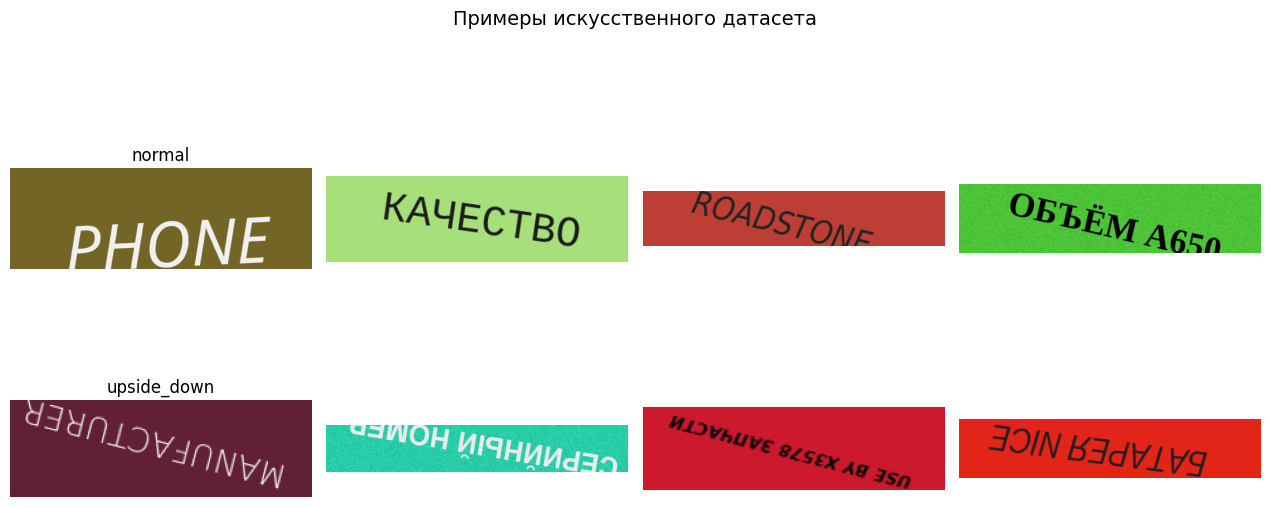

In [4]:
amount = 4
class_names = ["normal", "upside_down"]
fig, axes = plt.subplots(2, amount, figsize=(3.2 * amount, 6.4))
for row, class_name in enumerate(class_names):
    class_dir = train_dir / class_name
    files = []
    if class_dir.exists():
        for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp"):
            files.extend(class_dir.glob(ext))
    files = sorted(files)
    random.shuffle(files)
    for col in range(amount):
        ax = axes[row, col]
        if col < len(files):
            image = Image.open(files[col]).convert("RGB")
            ax.imshow(image)
            if col == 0:
                ax.set_title(class_name, fontsize=12)
        ax.axis("off")
fig.suptitle(f"Примеры искусственного датасета", fontsize=14)
plt.tight_layout()
plt.show()

## Обучение или загрузка модели

По умолчанию используется существующий `orientation_model.pth`. Чтобы обучить модель заново на имеющемся `orientation_dataset`, необходимо выставить `TRAIN_MODEL = True`. Повторное обучение может дать немного другой результат.

In [5]:
model = OrientationCNN().to(device)
if TRAIN_MODEL:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_score = -float("inf")

    for epoch in range(NUM_EPOCHS):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.float().to(device)
            optimizer.zero_grad()
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        model.eval()
        val_logits, val_labels = [], []
        with torch.inference_mode():
            for images, labels in val_loader:
                val_logits.extend(model(images.to(device)).squeeze(1).cpu().numpy())
                val_labels.extend(labels.numpy())
        val_logits = np.asarray(val_logits)
        val_labels = np.asarray(val_labels, dtype=np.float64)
        val_probs = 1.0 / (1.0 + np.exp(-val_logits))
        score, brier, accuracy = score_probabilities(val_probs, val_labels)
        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"train loss = {train_loss_sum / len(train_dataset):.4f} | "
            f"1-Brier = {score:.5f} | Brier = {brier:.5f} | accuracy = {accuracy:.4f}"
        )
        if score > best_score:
            best_score = score
            torch.save(model.state_dict(), MODEL_PATH)
            print("Сохранена лучшая модель:", MODEL_PATH)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Не найден {MODEL_PATH}"
    )
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print("Модель готова:", MODEL_PATH)

Модель готова: orientation_model.pth


## Валидация и подбор температуры

Предсказания исходного изображения объединяются с предсказаниями изображения, повёрнутого на 180°: `p = (p_original + 1 - p_rotated) / 2`. Температура выбирается по минимальному Brier Score на валидационной выборке.

In [7]:
TEMPERATURE = 0.36
best_temperature = TEMPERATURE
if val_dataset is not None:
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    val_probs, val_tta_probs, val_labels = [], [], []
    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            probs_original = torch.sigmoid(model(images).squeeze(1))
            probs_rotated = torch.sigmoid(model(torch.rot90(images, k=2, dims=(2, 3))).squeeze(1))
            probs_tta = (probs_original + 1.0 - probs_rotated) / 2.0
            val_probs.extend(probs_original.cpu().numpy())
            val_tta_probs.extend(probs_tta.cpu().numpy())
            val_labels.extend(labels.numpy())
    val_probs = np.asarray(val_probs, dtype=np.float64)
    val_tta_probs = np.asarray(val_tta_probs, dtype=np.float64)
    val_labels = np.asarray(val_labels, dtype=np.float64)

    def report(name, prob):
        score, brier, accuracy = score_probabilities(prob, val_labels)
        print(f"{name:26s} | 1-Brier = {score:.5f} | Brier = {brier:.5f} | accuracy = {accuracy:.4f}")

    report("CNN", val_probs)
    report("CNN + поворот 180°", val_tta_probs)

    def logits_from_probs(prob):
        prob = np.clip(prob, 1e-7, 1 - 1e-7)
        return np.log(prob / (1 - prob))

    temperatures = np.linspace(0.1, 0.8, 141)
    tta_logits = logits_from_probs(val_tta_probs)
    best_temperature = TEMPERATURE
    best_brier = float("inf")
    best_calibrated_val = val_tta_probs.copy()
    for temperature in temperatures:
        calibrated = 1.0 / (1.0 + np.exp(-tta_logits / temperature))
        brier = np.mean((calibrated - val_labels) ** 2)
        if brier < best_brier:
            best_brier = brier
            best_temperature = float(temperature)
            best_calibrated_val = calibrated

    report(f"Symm + T={best_temperature:.2f}", best_calibrated_val)
    print(f"Выбранная температура: {best_temperature:.2f}")
else:
    print(f"Validation не найден; используется ранее выбранная температура T={TEMPERATURE:.2f}.")

CNN                        | 1-Brier = 0.93003 | Brier = 0.06997 | accuracy = 0.9042
CNN + поворот 180°         | 1-Brier = 0.93789 | Brier = 0.06211 | accuracy = 0.9270
Symm + T=0.36              | 1-Brier = 0.94872 | Brier = 0.05128 | accuracy = 0.9270
Выбранная температура: 0.36


## Тестовые предсказания и `submission.csv`

Код ниже использует `images/test_*.png`.
Для воспроизведения текущих предсказаний нужны `orientation_model.pth` и тестовая папка `images`. Если валидационные данные доступны, температура подбирается на них; иначе используется ранее выбранное значение `0.36`.

In [8]:
test_files = sorted(TEST_DIR.glob("test_*.png"))
final_predictions = []

with torch.inference_mode():
    for start in range(0, len(test_files), BATCH_SIZE):
        batch_files = test_files[start:start + BATCH_SIZE]
        batch_images = []
        for path in batch_files:
            with Image.open(path) as image_file:
                batch_images.append(transform(image_file.convert("RGB")))
        x = torch.stack(batch_images).to(device)
        p_original = torch.sigmoid(model(x).squeeze(1))
        p_rotated = torch.sigmoid(model(torch.rot90(x, k=2, dims=(2, 3))).squeeze(1))
        p_tta = (p_original + 1.0 - p_rotated) / 2.0
        p_tta = p_tta.clamp(1e-7, 1.0 - 1e-7)
        z_tta = torch.log(p_tta / (1.0 - p_tta))
        p_calibrated = torch.sigmoid(z_tta / best_temperature)
        final_predictions.extend(p_calibrated.cpu().tolist())
        print(f"Обработано: {min(start + len(batch_files), len(test_files))}/{len(test_files)}")

with open(SUBMISSION_PATH, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["image_id", "p_180"])
    for path, probability in zip(test_files, final_predictions):
        writer.writerow([path.stem, f"{probability:.8f}"])

print("\nФайл создан:", SUBMISSION_PATH.resolve())
print("Количество предсказаний:", len(final_predictions))
if len(final_predictions) != 20000:
    print(f"Ожидалось 20000 изображений, найдено {len(final_predictions)}")

Обработано: 64/20000
Обработано: 128/20000
Обработано: 192/20000
Обработано: 256/20000
Обработано: 320/20000
Обработано: 384/20000
Обработано: 448/20000
Обработано: 512/20000
Обработано: 576/20000
Обработано: 640/20000
Обработано: 704/20000
Обработано: 768/20000
Обработано: 832/20000
Обработано: 896/20000
Обработано: 960/20000
Обработано: 1024/20000
Обработано: 1088/20000
Обработано: 1152/20000
Обработано: 1216/20000
Обработано: 1280/20000
Обработано: 1344/20000
Обработано: 1408/20000
Обработано: 1472/20000
Обработано: 1536/20000
Обработано: 1600/20000
Обработано: 1664/20000
Обработано: 1728/20000
Обработано: 1792/20000
Обработано: 1856/20000
Обработано: 1920/20000
Обработано: 1984/20000
Обработано: 2048/20000
Обработано: 2112/20000
Обработано: 2176/20000
Обработано: 2240/20000
Обработано: 2304/20000
Обработано: 2368/20000
Обработано: 2432/20000
Обработано: 2496/20000
Обработано: 2560/20000
Обработано: 2624/20000
Обработано: 2688/20000
Обработано: 2752/20000
Обработано: 2816/20000
Обра